# Variant 28: Fitness app retention
**Student: Bakhtiyar Makashev Sagandykovich · AI Fundamentals**

All observations and labels are **synthetic**. This notebook is standalone and does not import Streamlit or require a running website. In Google Colab, use **File → Upload notebook**, then **Runtime → Run all**. Outputs saved in this file were obtained by actual sequential local Python execution in the project environment, not by a Google-hosted Colab run. Rich Plotly outputs render in compatible notebook viewers. Different package versions can change numerical results; the archived data hash remains fixed.

## Part 1: Supervised learning


## Step 1 — Imports and experiment setup
Object: one user at week end. Inputs: workouts, streak, received notifications. Target: at least one workout next week, 1=active and 0=inactive. Split before fitted preprocessing.


In [1]:
# Install only missing packages. This cell is safe in Colab and local Python.
import importlib.util, subprocess, sys
packages = {"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3", "sklearn": "scikit-learn>=1.6,<2", "plotly": "plotly>=5.24,<7"}
MISSING = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if MISSING:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *MISSING])
import io, json, hashlib, base64, zlib, platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from itertools import combinations
from sklearn.base import clone
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
FEATURES = ["workouts", "streak", "notifications"]
TARGET = "active_next_week"
SEED = 42
print("Python:", platform.python_version())
print({name: version(name) for name in ["numpy", "pandas", "scikit-learn", "plotly"]})
def show_chart(fig):
    fig.update_layout(template="plotly_white", height=460, margin=dict(l=30, r=30, t=70, b=40))
    display(fig)

def show_map(embedding, labels, title):
    view = pd.DataFrame({"axis_1": embedding[:, 0], "axis_2": embedding[:, 1], "group": np.asarray(labels).astype(str)})
    show_chart(px.scatter(view, x="axis_1", y="axis_2", color="group", title=title, opacity=.7))


Python: 3.14.6
{'numpy': '2.5.5', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'plotly': '6.9.0'}


## Step 2 — Synthetic provenance and data inspection
The exact archived table is embedded so numerical results can be audited without regenerating a different sample. The original generator is included below for transparency, but model training uses the embedded snapshot. Workouts and notifications are Poisson-like counts, streak is Gamma-derived, and three overlapping generator regimes are discarded. Labels are Bernoulli draws from the documented noisy nonlinear activity function. Missing values are independently introduced after labels (MCAR). These are assumptions, not observed real user relationships. No real personal data are present.


In [2]:
# Embed the exact archived synthetic data: no upload, API key, app.py, or internet dataset is needed.
ARCHIVED_CSV = zlib.decompress(base64.b64decode("eJx1XM2OpbeN3edZbgKJFEXpJWaTVVaGkfQADQM2YHeSefz56koiD3nlRRnoUypK4p+OSH3+9x/ffv/p+79e//3t919++/ePP15//Pj928+/vH797cf3//3+z59/fP/t1z9eP//zx/f/fPvp12//9+On/3779stf/v6P//lrKaW+2t/Ki5+f/vzUA9OLnn/O50cQ5jdcv/7jYHuVL7B+/afgaHmPbucvysH7e66557Xhuv75JUIRH2+cMzxf7xnPnxzpde1k7J8zvFYbLg2H01sq1aSBurYqe2Yb3tZGOWusytroh5y+tJOVUPWNjT3c4PGGXzXImK6VNuEXVGyRjtXXe6CCVKItVRDkZdsjwQS010v6MdwB5a2GlrRKsDtUE+l7/pmUQeM9/P0nYSnTxaCNuZjpcTjX97Z1L8bgZcqS/Ir5LZjOGg1vjqNSWV7vfQasu7OhWlh94ej6PN4Llo85l9O2PGfbMs4vz5ZafW9J0nIavZbdcC1tB2dNgdJWfFJWbpO3bXpSV+vLwi3jurZz1mJLHK5GdKMGWyXAZW21ZJeRGpdpOPquCVl7Dc4lbS2wYjTIY8yZtCd9zfKxAjWFrGR28GXMkPRkRhkH72WvFqOkL3+l5K+dDAqjl79q9qneLE2jPvvKspyluMcGWC2OUXcdjBiET1t58Hst7gwoXquHHxpRyVSLgay8p8tZU5vFFaF6Vcx5BLOpdk8saDrVGOM2fp0p+XzTlYdOljujx9oRnZR2hg+3K252kPkG7mmsfKvzLPTgzfYUhIt7GJpkQCqqOKtaQkSLjGEGD8fkmPesOEF0mHfWmLsNJ0shOO9knxO3NZt7WRgvFv5oqLkMO/4Wc9pUM1TwyzlcORjaE/wYlFbLMlGzTHXwlXebWeDgZAcuxmZ9iFF5h30Q3jxICAd74lWEuwUyoxQ1EtIRHq4BQdztisLr/ueRbnhdrh2tVB9WdDvXa2V3goC390p0izJY3BwB72tW88CD6/rnySE2foQD34ZPI5iomocVuRgDfaNo0IcZsYUAegCxH0dB+NppSqCVxB1McXh3koX2IL2eQZU8EaM9NkHKebgyHLzoBVzdfqixhyItx0Zs56W0QqRHYbiYL+IKN0Mars3zi3WqZrpSH4rUbnLmGpVM3Up0SMPrNWgegtS2SnDOhyL1G9x8GegcTUywY90TOxq6aUzXhg+/XGHGeOjRK52edVMjY5lHxkON5GC4biHPgKhDYT+F0XelGeHA1F4FnHfi+O6MKqxTLZZ87PAbGu7zIUp4ezvDu4cQhlEHv0UNdPJMJzie48XBxjfTJKE1HrJ0chQqbJOlj7T2sKVxFIBe1xcjZM3Ln/fl69o8H8cz/Lmr5TtFVXLijN6oi/N+eN7DlU5ixPhVP1DDAbGpEuW9PlTp8B5UzcOU3owzW+qhSueajQZ5qJKdBIYt9w0afDjSPGJx85skcRbh9gRiVh+OtDYRltCtpIEbGXBVQ32M4bZHdT8EaXkyRtD0VBPS0KweibiWSR6JOOmEOylqdS5bfkGOiZ/0aPcJnBedaqpxlLCU4Ukk4O6zEONUSmTU5eB1aeV9dgv+AdmWGGH2yA3y3aLohlTEmX/B8d3TdphW4zlt+LidI1SmbwvF12KXLlx9dYaPMUqVnPAGMcmuZ1fVY5RwuB8wNeDdgmgi7GcMDZQ+rocj1RWjmnf1RZD0zHmEUDXhE+GVeSmFEz386FatI3IPRsWQXL2Mut1nUb0ERkXno3XInDkNnr7GYCYu0ckMd9YQ9M4rK9nFxfCVlXKRkLgZn3BM9t+eg8Z+0dcvWgnD1w01aIWH36BR5zzBcVE0sCPUS1tZKSz5YUYnwQoOXY6bbnHU2q1yQbt0lFMvndrRPEo/uNqENeDDyFRD8R6kglEkxaMx4NVOP1SXrK1SSZuSlZLiWC84BFiueZqkW+AGyWr0At1QhkNon4cbfZzPtCtI+fgnoEYYnw8zqrbBMN4tiqVGeqjREoQGfXjROBHkI4EpoHm6Rydh6PcRyZjhfk0L0anFVxjwumtoGPqbFdm5YDhfyyG0WVEqWJPK1aEfUnSyFpp5l4+MMxi+SNFbhZhXHlJkdkANDF8IbnR4TyKkm0HXUigNvqfFARVeTOm7hHR4molfbDcRBBp/cpIOqKlg0hnO7IPjzV0DyOPnooGJ8dEk9wLU5WQnngFfm00lcZqr/9JSSY/msizlqi7NfS9NPQqawwM1zDtXwozyubgiB8J+woAFubgXY0jxZkmJw/MmSZLhc8Qkh+LS7WIWxi83nlgZ5+KFwYljoS4IEcK1XOOM6zpjsrW5kh32qIDKMaIMb87LCHExHMOed1vNrrg2rV4LVFw9BU+Epyk4LGc31ig1QZhWXZCS0/AuI6Vsww9JevWRPJuBIoXB4iGJcLfuQw24OkkISxm3ojTTNKqCrsFQV0HpXK2AgqmJGQqD6B7MFhk4K68SaEtBzCzXDMe8HBhrOcxqoURhKdeiIO8W23s4imneccaQaamsbcPJu3RhPPuBhf6+mdKHwprYYYMKaP2WmrmtSOWaZx3u7mFT0wgHihFIwRg1sqyayh8sZMMbGlVWsAaHkWaO4Zg3+tETN0n68H9ZlQZKGZbFM1IQM83OOPrhSR+Ekh+S9L47o2W6X0yRNTLWjjCj9ea3LLRk98saKq+vu1pQ0u6y5fR8ykZZwrwe36xbd6lEyurt7zgeDhc040OR1k5x97q6iZ+DF+NdWQv3pD3wT4PV6uFoHR3eoDXR86rAAVvBCUfdBZgQTw83eltL0l2MB5tvh4NoNPP3IF3u1h+LL4QMNNTTr+Aux3B2jKRgU6NcU+K5E0FJa59uUVzjTF0Yw32rGPWzeWka3Q4LSJjiZjd+EoarxVqAvTPhEua1Vd0K+AkhXq/t2FbIqCHjcK94KsLtyiHa7qtlVtTKupVyIrytQEVQUc5+vNGznBkJ8hlft/uXNH4/OTqM1IbTXWlYO6qIN+8+ozKrN4gnwj3uynCg92E5w/szqPwK76uAqjZaSw+a3LWjFAaN7pm3EWReVBh5y8kxaIOjVh5aVG8l10bQGmacdPhznDB+3hfJ+8hJl/nG1R+M4YIYqg0dcXfiAC9mRD0tB5gREt7G/RrEjeGKGpY/vMWKbvDQo/zar7VznqP9W7U1D4TJ+6hw+LTm7+Vwuv34KPP01hIBNLx76xadvfnbHMeGk2W0xH55lO8ATYrNaWOlOlNC9Yk/gAxBKvzREmzSYqQYLn+CQ4SiKXf1qKbM23b5yDqoNn5aSRxV2MuNirdeb33b1s/zqiCC/UhG54S2WtBWF7ACqquDOcME/qghjh9rmP3y4POeG9WLwRG/HqhtP0PKHKHtIpLlDMPb3cM0vc05eng40qfbqW6Xw43q8HcBGF7qZDfMuElSDq9RvQcRcHq94qE2oF4fJcPNG71uyF3loxvxQD8aapwkLGTcs+uY91MHG2w462mwJdbXJplOArxPmJL1O//Egx+OlN+TtocfZV7bdnPt4/Cew9JfmG46JQMxUoBfFcSrbx+yv+y6EZsuD85+qE3Emxfcw3hxPMwLcRp/oZ5LCRc01m2a8oKm3XzADaRC4QzXWWt0D8Ppow8qFaqfqMuHH310s+UhRx9OJEiNBg6GolEYPwL/tOFz5+j8vFfonFwnVu0XUDdC9RLZzCYe2REcD0IN9o62IDhLG+LQIA6CdOcGtBANr5OiQe91I8G6Ec7JFZ66oGqYYoq1P+BXvicLey0liJD9yG4g2F9WCzaZalGETnXaal8/YS9zP63p2Q0buCwqpa1StqTikHy9yz6lwbOYUzA6uzd8bbKl1CXIjMKc/cax5bw7+sD9WUNYzUpIIVlIsVY5qkW8shtG00UCvz6onEizCx3uD1gR2ky6le18qN7jVYb5EmpoF4qI0ozdO3IBrp7aMLw7lFECzlbFwxDenCi7yK4WeVY9eA8NKIMXIaKsrT6cn2LY9BlP7YOrc1xcO77LxnNF99cv6Ymq7LdG51ix4e0Oy9p+Xrx2cyr0FtVrCVU2J5o5CnXeuI+M4h1BFDOqLTAMd6aAa3940YqddI+WXTeibKmxyvRs+jy4PzvCxY97kUHGuBb9ZEx/moCBO8vd4A8xeqeW/JZWprckMC/gyyNUz/SqZ5hWouPY8B671DZeTfmozLlT78irARoIWuvFW2eKsJsWFtm/2NHb4yWLYa8+B9wPmIHw6oK3VCjqpZsaA7wvMSOLSc9xbJkTupygzF6L8QxCuFq/Chdf4U1ZwHfDNDlmf/jRuInxAqitsPoZg2qv/qKshgXeG/69wm0NFUbwPCzg9eY0nTwRA33p5HkYt0nrHpOYZ99dtbqYwwG7MwHcEHmrKeLpFmP4tBjDOXn7Q2pZdK6vjxf4fX+1NjLMVxrQeW2zz2Nq+8XXW0h/CnJQP26CL7K+rD9rY4ddDnCT7M830GgNHjWj1Vp9fTyA6G09rOKskf3syJrZhrcYQoZLcAmD93Ocj2kh+WLCaPCkAXXY5u31acd2GtpC/JsCxuWI18jQcXftqObbVxe4gk/8g9PnT8XDvslSoPV9t9U41fO7QJQWHD+fK28qHPTu9scJkSvhnPsTto/h92fZfbfWssv0VCiz4d16S2HSFaW95lnXFaalymzH/hoqQMGD0fm0fmZGJaPSaCHl63uAvrtrlCXL9VhT+CAR3XT31sgevh58eHkO9ahQskeFAVOKuLNC3NSge9QMJ4XBTKN5MQP1vp8ffbg7fMGGqx/7A9N0IepjxPaKTetMCTPbPA8eMVInvLRC2ZO8BhNwvrL3vllSAsXuFpgFprf40dj70zV3rf0we+QlwPMqIIha7jdv3V/y51qlFrh4d8Q5WMHEtJVxNUWRfj06WrezIKW/MtPW4g3EAA+zV5AwLcDBG7QW9wbUtn6VjM6B2xCn8OD77KeuXimnYoKertqMIar1+qG77tJRpkC6qRHlzdb7vU2rOy3ulqDVj6uk6v6DmyWyJCIIu01RB/DgKAiHz36CcH9FFnG1K3pYu3/UrzjpvJYgdVeOTmI3GN6RBZw+krEyfIUIlw9lf9OA28fHRgVxZ7txyvurT2V3YKS7uglSenmordzqJ9rgkwKU0shwjMf9yVpuW2rzQraPFds/RtiuHFGqtWuDfWKkN/+UC0OgzVuHTwWeQcO6pZqzIINTgbetqPSvElKme7o/WEsFBBWxlIELlHuLVAVYfZC+DhaytHnwueuMcPhp99MczdD35zDt4xdQRcIE0J3xOubvdwkXcj7tNy89eL8yOu1/YtB+b8Iofq6G47WEWoDBzouwNa2bG9WSi76qbJdaNJTi/0QljL9/s6a630BmD96VpJ7lO713bFriwqHD3QiTFDCj4KUPNRrH2gHnGwXQAV+Ah1nlmpCHP7hHd99f9i/TIX4vIekmRqn0q9MPWbTqPN8gooj9KDtxF53+ytOxdrcZfNDPYRk9ZmOTA1Ea8GGJJATH/m4tv4IbxSnGyqP/D/QIlhQ="))
EXPECTED_HASH = "d0526e53c4a5929c8808f73065a2c8cd1eedb00146d18171a476dfe29f0369ed"
assert hashlib.sha256(ARCHIVED_CSV).hexdigest() == EXPECTED_HASH
frame = pd.read_csv(io.BytesIO(ARCHIVED_CSV))
assert frame.shape == (800, 5) and frame.user_id.is_unique
assert set(frame[TARGET].unique()) == {0, 1}
print("SYNTHETIC inputs and target labels; dataset SHA-256 verified.")
print("Shape:", frame.shape)
display(frame.head())
display(frame[FEATURES].describe().T)
display(pd.DataFrame({"missing": frame.isna().sum(), "missing_fraction": frame.isna().mean()}))
print("Class balance:", frame[TARGET].value_counts().to_dict())


SYNTHETIC inputs and target labels; dataset SHA-256 verified.
Shape: (800, 5)


,user_id,workouts,streak,notifications,active_next_week
0,SYN-0001,4.0,3.0,6.0,1
1,SYN-0002,2.0,9.0,5.0,1
2,SYN-0003,2.0,12.0,NaN,1
3,SYN-0004,0.0,11.0,10.0,1
4,SYN-0005,2.0,4.0,12.0,0


,count,mean,std,min,25%,50%,75%,max
workouts,760.0,2.884211,2.734113,0.0,1.0,2.0,4.0,14.0
streak,770.0,8.666234,13.741966,0.0,2.0,4.0,9.0,110.0
notifications,771.0,9.892348,6.194684,0.0,6.0,9.0,13.0,56.0


,missing,missing_fraction
user_id,0,0.00000
workouts,40,0.05000
streak,30,0.03750
notifications,29,0.03625
active_next_week,0,0.00000


Class balance: {1: 560, 0: 240}


In [3]:
def generate_data(n: int=800, seed: int=42, missing: float=0.05) -> pd.DataFrame:
    """Generate reproducible synthetic inputs AND labels; never present as real logs."""
    if not 600 <= n <= 1000 or not 0 <= missing <= 0.2:
        raise ValueError('n must be 600–1000; missing must be 0–0.20')
    rng = np.random.default_rng(seed)
    mode = rng.choice(3, n, p=[0.38, 0.42, 0.2])
    workouts = np.clip(rng.poisson(np.array([0.8, 3.1, 6.0])[mode]), 0, 14).astype(float)
    streak = np.clip(np.rint(rng.gamma(1.7, np.array([1.0, 4.0, 12.0])[mode])), 0, 120)
    notifications = np.clip(rng.poisson(np.array([14.0, 8.0, 4.0])[mode]), 0, 60).astype(float)
    unusual = rng.choice(n, max(1, int(n * 0.03)), replace=False)
    for i, idx in enumerate(unusual):
        if i % 3 == 0:
            workouts[idx], streak[idx] = (rng.integers(0, 2), rng.integers(60, 121))
        elif i % 3 == 1:
            notifications[idx] = rng.integers(35, 61)
        else:
            workouts[idx], streak[idx] = (rng.integers(10, 15), rng.integers(40, 91))
    z = -2 + 0.55 * workouts + 0.9 * np.log1p(streak) + 0.07 * np.minimum(notifications, 10) - 0.06 * np.maximum(notifications - 10, 0) - 0.1 * np.maximum(workouts - 9, 0) ** 2 + rng.normal(0, 0.75, n)
    target = rng.binomial(1, 1 / (1 + np.exp(-np.clip(z, -30, 30))))
    values = np.column_stack([workouts, streak, notifications])
    values[rng.random(values.shape) < missing] = np.nan
    frame = pd.DataFrame(values, columns=FEATURES)
    frame.insert(0, 'user_id', [f'SYN-{i + 1:04d}' for i in range(n)])
    frame[TARGET] = target
    return frame


## Step 3 — Training-only exploratory plots
A separate stratified index split identifies training rows before EDA. Histograms exclude NaN. Different units and right tails motivate scaling and median imputation.


In [4]:
train_index, test_index = train_test_split(frame.index, test_size=.20, stratify=frame[TARGET], random_state=SEED)
for feature in FEATURES:
    show_chart(px.histogram(frame.loc[train_index], x=feature, nbins=30, title=f"Training distribution: {feature}"))
display(frame.loc[train_index, FEATURES].describe().T)
show_chart(px.bar(frame.loc[train_index, TARGET].value_counts().rename_axis("class").reset_index(name="users"), x="class", y="users", title="Training class balance"))


Training distribution: workouts

Training distribution: streak

Training distribution: notifications

,count,mean,std,min,25%,50%,75%,max
workouts,605.0,2.877686,2.736481,0.0,1.0,2.0,4.0,14.0
streak,616.0,8.659091,14.115459,0.0,2.0,4.0,9.0,110.0
notifications,618.0,9.828479,5.881022,0.0,6.0,9.0,13.0,56.0


Training class balance

## Step 4 — Split 80/20 before preprocessing
Training rows support CV; the test set is held out. Each pipeline learns its own imputation and scaling values inside each fold.


In [5]:
def prepare(strategy: str='median', scaled: bool=True) -> Pipeline:
    """Fresh preprocessing for each fit; unsupervised analysis never reuses supervised fit."""
    return Pipeline([('imputer', SimpleImputer(strategy=strategy, keep_empty_features=True)), ('scaler', StandardScaler() if scaled else 'passthrough')])

def metrics(y: np.ndarray, pred: np.ndarray, prob: np.ndarray) -> dict:
    return {'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred, zero_division=0), 'f1': f1_score(y, pred, zero_division=0), 'roc_auc': roc_auc_score(y, prob)}
Xtr, Xte, ytr, yte = train_test_split(frame[FEATURES], frame[TARGET], test_size=.20, stratify=frame[TARGET], random_state=SEED)
assert len(Xtr) == 640 and len(Xte) == 160
print("Train:", Xtr.shape, "Test:", Xte.shape)
print("Training classes:", ytr.value_counts().to_dict())
print("Test classes:", yte.value_counts().to_dict())
folds = list(StratifiedKFold(3, shuffle=True, random_state=SEED).split(Xtr, ytr))


Train: (640, 3) Test: (160, 3)
Training classes: {1: 448, 0: 192}
Test classes: {1: 112, 0: 48}


## Step 5 — Logistic Regression pipeline
Median imputation is robust to tails; StandardScaler puts predictors on comparable scales for a regularized LR model. No test evaluation is used for selection.


In [6]:
lr = Pipeline(prepare().steps + [("classifier", LogisticRegression(max_iter=2000, random_state=SEED))])
lr.fit(Xtr, ytr)
print(lr)
print("Training medians:", dict(zip(FEATURES, lr.named_steps["imputer"].statistics_)))


Pipeline(steps=[('imputer',
                 SimpleImputer(keep_empty_features=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=42))])
Training medians: {'workouts': np.float64(2.0), 'streak': np.float64(4.0), 'notifications': np.float64(9.0)}


## Step 6 — Error definitions and majority baseline
Positive means active. FP can miss an inactive user for retention support. FN can lead to unnecessary outreach. Confusion matrices are evaluated after the model selection in Step 10.


In [7]:
baseline = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
print("Baseline rule:", baseline.predict(Xte.iloc[:1])[0], "for every user")
print("Use identical test rows and threshold 0.5 after CV selection.")


Baseline rule: 1 for every user
Use identical test rows and threshold 0.5 after CV selection.


## Step 7 — Three-fold stratified CV
The full LR pipeline is refitted within each of the same three training folds. SD measures fold variation, not a confidence interval.


In [8]:
lr_cv = cross_val_score(lr, Xtr, ytr, cv=folds, scoring="f1", n_jobs=1)
print("LR fold F1:", lr_cv)
print("Mean:", lr_cv.mean(), "SD:", lr_cv.std())


LR fold F1: [0.83766234 0.85526316 0.82428115]
Mean: 0.8390688819056064 SD: 0.012687394685381919


## Step 8 — Standardized LR coefficients
Coefficients describe fitted conditional log-odds associations, not percentage-point or causal effects.


In [9]:
coefficients = pd.DataFrame({"feature": FEATURES, "coefficient": lr.named_steps["classifier"].coef_[0]}).sort_values("coefficient")
display(coefficients)
show_chart(px.bar(coefficients, x="coefficient", y="feature", orientation="h", title="LR: standardized coefficients"))


,feature,coefficient
2,notifications,-0.246179
0,workouts,1.162055
1,streak,1.519784


LR: standardized coefficients

## Step 9 — Random Forest with identical folds
150 trees, max depth 6, minimum leaf size 3. Scaling is retained for the shared workflow even though trees generally do not require it.


In [10]:
rf = Pipeline(prepare().steps + [("classifier", RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=3, n_jobs=1, random_state=SEED))])
rf_cv = cross_val_score(rf, Xtr, ytr, cv=folds, scoring="f1", n_jobs=1)
cv_table = pd.DataFrame({"model": ["Logistic Regression", "Random Forest"], "fold_1": [lr_cv[0], rf_cv[0]], "fold_2": [lr_cv[1], rf_cv[1]], "fold_3": [lr_cv[2], rf_cv[2]], "mean_f1": [lr_cv.mean(), rf_cv.mean()], "sd_f1": [lr_cv.std(), rf_cv.std()]})
display(cv_table)
show_chart(px.bar(cv_table, x="model", y="mean_f1", error_y="sd_f1", range_y=[0, 1], title="Training-only CV F1"))


,model,fold_1,fold_2,fold_3,mean_f1,sd_f1
0,Logistic Regression,0.837662,0.855263,0.824281,0.839069,0.012687
1,Random Forest,0.837838,0.852234,0.816720,0.835597,0.014585


Training-only CV F1

## Step 10 — Select by CV, then final test evaluation
The test comparison is descriptive after selection. Do not change the winner using test scores. The majority baseline may have a higher positive-class F1 because activity prevalence is 70%.


In [11]:
winner = "Random Forest" if rf_cv.mean() > lr_cv.mean() else "Logistic Regression"
models = {"Logistic Regression": lr, "Random Forest": rf}
selected = models[winner]
print("Selected using TRAINING CV only:", winner)
probabilities, test_rows = {}, []
for name, model in models.items():
    model.fit(Xtr, ytr)
    probability = model.predict_proba(Xte)[:, 1]
    prediction = (probability >= .5).astype(int)
    probabilities[name] = probability
    test_rows.append({"model": name, **metrics(yte, prediction, probability)})
    cm = confusion_matrix(yte, prediction, labels=[0, 1])
    print(name, "confusion matrix:", cm.tolist())
    print(classification_report(yte, prediction, zero_division=0))
    show_chart(px.imshow(cm, text_auto=True, x=["0: inactive", "1: active"], y=["0: inactive", "1: active"], labels={"x":"Predicted", "y":"Actual"}, title=name+" — test confusion matrix"))
pb = baseline.predict_proba(Xte)[:, list(baseline.classes_).index(1)]
test_rows.append({"model": "Dummy: majority", **metrics(yte, baseline.predict(Xte), pb)})
test_table = pd.DataFrame(test_rows).set_index("model")
display(test_table)
roc = go.Figure()
for name, probability in probabilities.items():
    fpr, tpr, _ = roc_curve(yte, probability)
    roc.add_scatter(x=fpr, y=tpr, mode="lines", name=f"{name}: AUC={roc_auc_score(yte, probability):.4f}")
roc.add_scatter(x=[0, 1], y=[0, 1], mode="lines", name="Chance")
show_chart(roc.update_layout(title="Held-out ROC", xaxis_title="False positive rate", yaxis_title="True positive rate"))
assert winner == "Logistic Regression"
assert np.isclose(test_table.loc[winner, "f1"], 0.8177777777777778)
assert np.isclose(test_table.loc[winner, "roc_auc"], 0.7975260416666665)
print("Archived selected-model F1/AUC reproduced.")


Selected using TRAINING CV only: Logistic Regression
Logistic Regression confusion matrix: [[27, 21], [20, 92]]
              precision    recall  f1-score   support

           0       0.57      0.56      0.57        48
           1       0.81      0.82      0.82       112

    accuracy                           0.74       160
   macro avg       0.69      0.69      0.69       160
weighted avg       0.74      0.74      0.74       160



Logistic Regression — test confusion matrix

Random Forest confusion matrix: [[28, 20], [21, 91]]
              precision    recall  f1-score   support

           0       0.57      0.58      0.58        48
           1       0.82      0.81      0.82       112

    accuracy                           0.74       160
   macro avg       0.70      0.70      0.70       160
weighted avg       0.75      0.74      0.74       160



Random Forest — test confusion matrix

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.74375,0.814159,0.821429,0.817778,0.797526
Random Forest,0.74375,0.819820,0.812500,0.816143,0.780971
Dummy: majority,0.70000,0.700000,1.000000,0.823529,0.500000


Held-out ROC

Archived selected-model F1/AUC reproduced.


## Step 11 — RF feature importance and error costs
Impurity importance ranks split contributions, with no direction or causal meaning. Costs below are illustrative assumptions.


,feature,importance
2,notifications,0.275365
0,workouts,0.333025
1,streak,0.391610


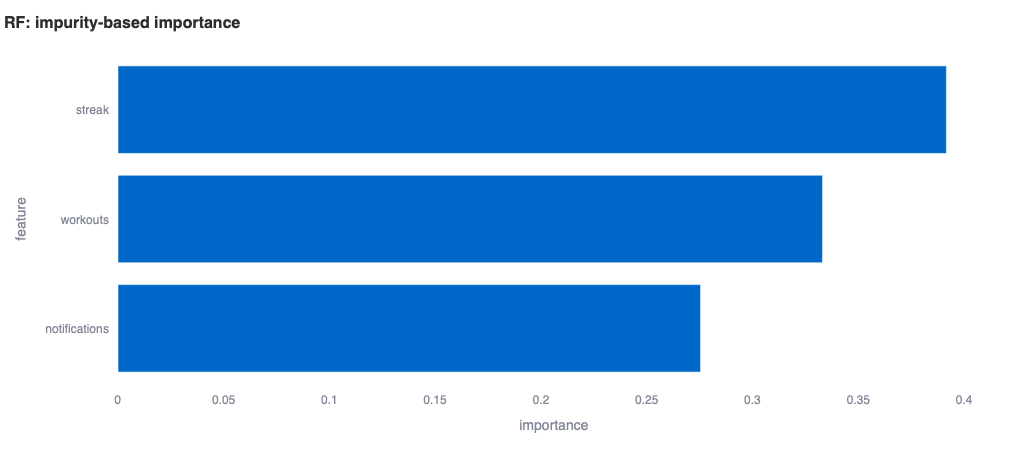

OOF-selected activity threshold for assumed FP/FN costs 5/1: 0.81


Training OOF cost by threshold

Logistic Regression cost/user at threshold .5: 0.78125
Random Forest cost/user at threshold .5: 0.75625
The optimized OOF minimum is optimistic after selection. Confirm on a separate validation cohort.


In [12]:
def cost_threshold(result: dict, fp_cost: float, fn_cost: float) -> tuple[float, pd.DataFrame]:
    """Tune on training OOF predictions, never test. Costs are user assumptions."""
    y = result['ytr'].to_numpy()
    rows = []
    for threshold in np.linspace(0.01, 0.99, 99):
        pred = result['oof'] >= threshold
        fp = int(((y == 0) & pred).sum())
        fn = int(((y == 1) & ~pred).sum())
        rows.append({'threshold': threshold, 'FP': fp, 'FN': fn, 'cost_per_user': (fp_cost * fp + fn_cost * fn) / len(y)})
    table = pd.DataFrame(rows)
    return (float(table.loc[table.cost_per_user.idxmin(), 'threshold']), table)
importance = pd.DataFrame({"feature": FEATURES, "importance": rf.named_steps["classifier"].feature_importances_}).sort_values("importance")
display(importance)
show_chart(px.bar(importance, x="importance", y="feature", orientation="h", title="RF: impurity-based importance"))
oof = cross_val_predict(clone(selected), Xtr, ytr, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
threshold, costs = cost_threshold({"oof": oof, "ytr": ytr}, 5., 1.)
print("OOF-selected activity threshold for assumed FP/FN costs 5/1:", threshold)
show_chart(px.line(costs, x="threshold", y="cost_per_user", title="Training OOF cost by threshold"))
for name, probability in probabilities.items():
    cm = confusion_matrix(yte, probability >= .5, labels=[0,1])
    print(name, "cost/user at threshold .5:", (5*cm[0,1]+cm[1,0])/len(yte))
print("The optimized OOF minimum is optimistic after selection. Confirm on a separate validation cohort.")


## Step 12 — Predict new users and conclude
Bounded known inputs and all-missing input test pipeline behavior. Neither probability is an independent real-world validation.


In [13]:
new_users = pd.DataFrame([{ "workouts":3., "streak":7., "notifications":8.}, {"workouts":np.nan, "streak":np.nan, "notifications":np.nan}], columns=FEATURES)
new_users["predicted_probability_1"] = selected.predict_proba(new_users)[:,1]
new_users["predicted_class"] = (new_users["predicted_probability_1"] >= .5).astype(int)
display(new_users)
print("Synthetic evidence only. LR improves accuracy and AUC, but its positive-class test F1 is below the always-active baseline.")
print("Next steps: real consented logs, temporal/grouped splitting, calibration, and randomized intervention evaluation.")
OUTPUT_DIR = Path("supervised_outputs"); OUTPUT_DIR.mkdir(exist_ok=True)
cv_table.to_csv(OUTPUT_DIR/"cv.csv", index=False)
test_table.to_csv(OUTPUT_DIR/"test_metrics.csv")
importance.to_csv(OUTPUT_DIR/"rf_importance.csv", index=False)
coefficients.to_csv(OUTPUT_DIR/"lr_coefficients.csv", index=False)
print("Saved CSV files in", OUTPUT_DIR)


,workouts,streak,notifications,predicted_probability_1,predicted_class
0,3.0,7.0,8.0,0.831503,1
1,NaN,NaN,NaN,0.687609,1


Synthetic evidence only. LR improves accuracy and AUC, but its positive-class test F1 is below the always-active baseline.
Next steps: real consented logs, temporal/grouped splitting, calibration, and randomized intervention evaluation.
Saved CSV files in supervised_outputs


## Worksheet answers and limitations
1. Public observations can measure actual outcomes; this dataset's inputs and labels are generated assumptions.
2. Variant 28 uses workouts, streak, and notifications. Target 1 means at least one workout next week.
3. Split before preprocessing because imputers/scalers learn statistics. CV also needs a fresh pipeline per fold.
4. LR has higher mean training CV F1, 0.8391 versus 0.8356. The difference is small.
5. Selected LR has FP=21, FN=20 at threshold .5. FP is missed inactivity; FN is unnecessary outreach.
6. Coefficients describe conditional log-odds; RF importance describes impurity reduction. Neither proves causality.
7. The all-active baseline's positive F1 is higher. It has zero inactive recall and AUC .5, so report all metrics honestly.

Sources: supplied Practice 8 worksheet; the app's archived synthetic data; [scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
